In [1]:
import numpy as np
import pandas as pd

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()

In [3]:
X = pd.DataFrame(iris.data, columns= iris.feature_names)
y = pd.DataFrame(iris.target, columns= ['Species'])

In [4]:
data = pd.concat([X,y], axis = 1)

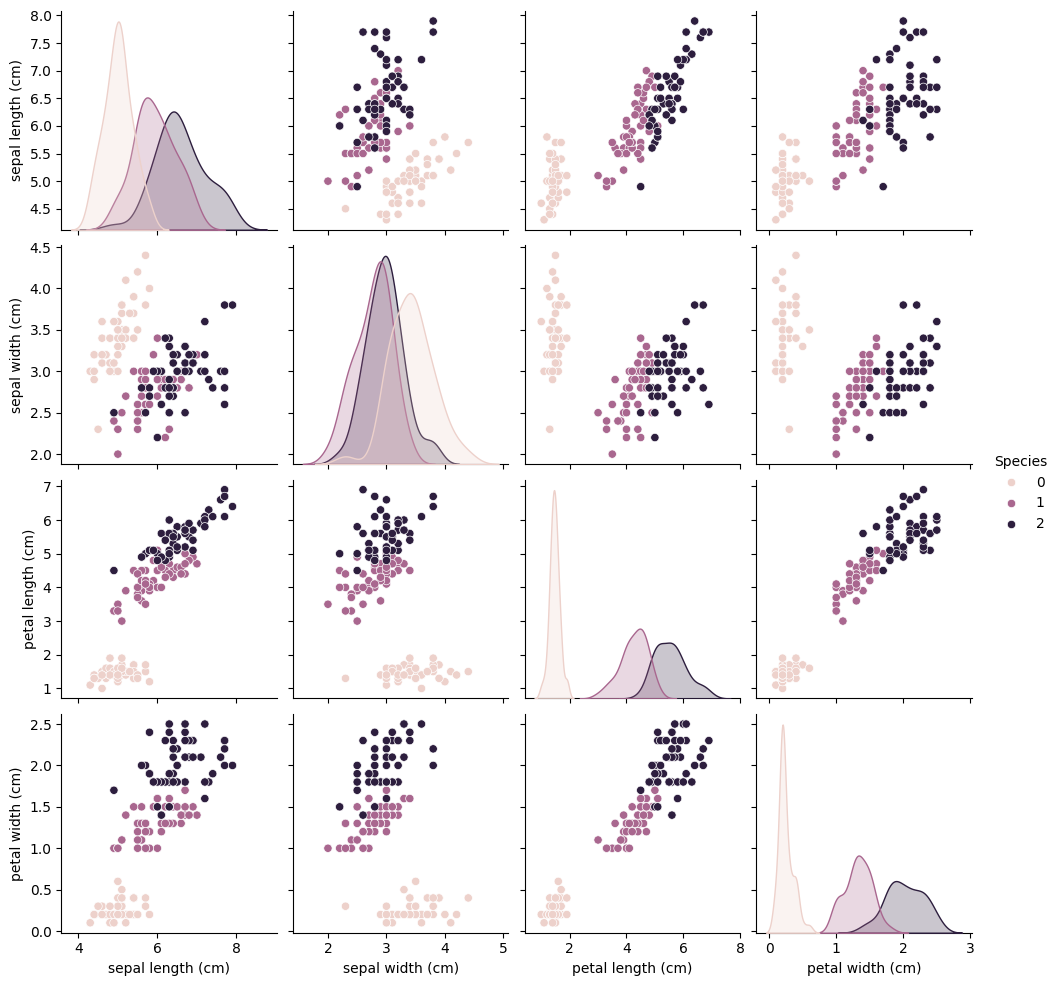

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.pairplot(data, hue='Species')
sns.set_context("paper", rc={"figure.figsize": (6,5)})
plt.show()

In [6]:
new_df = data[data['Species'] != 0][["sepal length (cm)", "sepal width (cm)", "Species"]]

In [7]:
new_df.head()

,sepal length (cm),sepal width (cm),Species
50,7.0,3.2,1
51,6.4,3.2,1
52,6.9,3.1,1
53,5.5,2.3,1
54,6.5,2.8,1


In [8]:
X = new_df.iloc[:,0:2]
y = new_df.iloc[:,-1]

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

In [10]:
clf1 = LogisticRegression()
clf2 = RandomForestClassifier()
clf3 = KNeighborsClassifier()

In [11]:
estimators = [('lr',clf1),('rf',clf2),('knn',clf3)]

In [12]:
for estimator in estimators:
    x = cross_val_score(estimator[1],X,y,cv=10,scoring='accuracy')
    print(estimator[0],np.round(np.mean(x),2))

lr 0.75
rf 0.6
knn 0.62


In [13]:
from sklearn.ensemble import VotingClassifier

## Hard Voting

In [14]:
vc = VotingClassifier(estimators= estimators, voting= 'hard')

print(np.mean(cross_val_score(vc, X,y, cv = 10, scoring= 'accuracy')))

0.6699999999999999


## soft voting

In [15]:
vc2 = VotingClassifier(estimators= estimators, voting= 'soft')

print(np.mean(cross_val_score(vc2, X,y, cv = 10, scoring= 'accuracy')))

0.6399999999999999


## Weighted Voting

In [16]:
for i in range(1,4):
    for j in range(1,4):
        for k in range(1,4):
            vc = VotingClassifier(estimators=estimators,voting='soft',weights=[i,j,k])
            x = cross_val_score(vc,X,y,cv=10,scoring='accuracy')
            print("for i={},j={},k={}".format(i,j,k),np.round(np.mean(x),2))
            

for i=1,j=1,k=1 0.64
for i=1,j=1,k=2 0.66
for i=1,j=1,k=3 0.65
for i=1,j=2,k=1 0.64
for i=1,j=2,k=2 0.65
for i=1,j=2,k=3 0.63
for i=1,j=3,k=1 0.61
for i=1,j=3,k=2 0.63
for i=1,j=3,k=3 0.64
for i=2,j=1,k=1 0.67
for i=2,j=1,k=2 0.66
for i=2,j=1,k=3 0.67
for i=2,j=2,k=1 0.65
for i=2,j=2,k=2 0.64
for i=2,j=2,k=3 0.64
for i=2,j=3,k=1 0.61
for i=2,j=3,k=2 0.64
for i=2,j=3,k=3 0.65
for i=3,j=1,k=1 0.71
for i=3,j=1,k=2 0.69
for i=3,j=1,k=3 0.69
for i=3,j=2,k=1 0.69
for i=3,j=2,k=2 0.67
for i=3,j=2,k=3 0.64
for i=3,j=3,k=1 0.67
for i=3,j=3,k=2 0.65
for i=3,j=3,k=3 0.66


## From Hands on Machine learning book

In [27]:
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X,y = make_moons(n_samples= 500, noise = 0.3 , random_state= 42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state= 42)

In [28]:
voting_clf = VotingClassifier(
    estimators = [
        ('lr', LogisticRegression(random_state= 42)),
        ('rf', RandomForestClassifier(random_state= 42)),
        ('svc', SVC(random_state= 42))
    ],
    voting= 'hard'
)

In [29]:
voting_clf.fit(X_train, y_train)

VotingClassifier(estimators=[('lr', LogisticRegression(random_state=42)),
                             ('rf', RandomForestClassifier(random_state=42)),
                             ('svc', SVC(random_state=42))])

In [30]:
for name, clf in voting_clf.named_estimators_.items():
    print(name, "=", clf.score(X_test, y_test))

lr = 0.864
rf = 0.896
svc = 0.896


In [31]:
voting_clf.score(X_test, y_test)

0.912

In [32]:
voting_clf.predict(X_test[:1])

array([1])

In [34]:
[clf.predict(X_test[:1]) for clf in voting_clf.estimators_]

[array([1]), array([1]), array([0])]

#### Applying soft margin 

In [35]:
voting_clf.voting = 'soft'

In [37]:
voting_clf.named_estimators["svc"].probability = True

In [38]:
voting_clf.fit(X_train, y_train)

VotingClassifier(estimators=[('lr', LogisticRegression(random_state=42)),
                             ('rf', RandomForestClassifier(random_state=42)),
                             ('svc', SVC(probability=True, random_state=42))],
                 voting='soft')

In [39]:
voting_clf.score(X_test, y_test)

0.92